In [ ]:
import pandas as pd
import numpy as np
from google.colab import files

# Upload the Excel Arabica_Supplier_Selection_Inputdata file
uploaded = files.upload()
file_path = next(iter(uploaded))

# Read input data
suppliers = pd.read_excel(
    file_path,
    sheet_name="Supplier_Data",
    header=3,
    nrows=8
)

criteria = pd.read_excel(
    file_path,
    sheet_name="Criteria_Matrix",
    header=2,
    nrows=4
)

parameters = pd.read_excel(
    file_path,
    sheet_name="Parameters",
    header=None,
    usecols="A:B"
)

params = dict(zip(parameters[0], parameters[1]))

print("Suppliers:", len(suppliers))
print("Criteria:", len(criteria))
display(suppliers.head())
display(criteria)

Saving Arabica_Supplier_Selection_v2.xlsx to Arabica_Supplier_Selection_v2.xlsx
Suppliers: 8
Criteria: 4


,Supplier ID,Warehouse location,EXW USD/MT,Distance km,Logistics USD/MT,Delivered USD/MT,Moisture %,Quality metric (Full defects / 300g),Certificate (0/1),OTD 0–100,T1 Origin,T2 Lot ID,T3 Lot-origin link,T4 Movement records,T5 Verification,Trace score 0–100,Eligible (1/0),Logistics % of EXW (helper)
0,S01,"Da Lat, Lam Dong",6200,303,20.5,6220.5,12.2,3,1,90,1,1,1,1,1,100,1,0.003306
1,S02,"Nha Trang, Khanh Hoa",6450,382,24.8,6474.8,12.6,25,1,82,1,0,0,0,0,20,0,0.003845
2,S03,"Thu Dau Mot, Binh Duong",7000,38,6.2,7006.2,11.7,8,1,86,1,1,0,1,1,80,1,0.000886
3,S04,"Binh Tan, Ho Chi Minh City",6550,32,6.1,6556.1,11.5,10,1,96,1,1,0,1,1,80,1,0.000931
4,S05,"Son La city, Son La",6000,1777,87.1,6087.1,11.3,5,1,86,1,1,1,1,1,100,1,0.014517


,Criterion,Direction,Base,Cost-focused,Traceability-focused,Measurement / rule
0,Delivered Cost,Cost,0.4,0.70,0.40,"EXW price (USD/MT), logistics cost (Transporta..."
1,Product Quality,Cost,0.2,0.15,0.20,Full defects per 300 g after specification pas...
2,On-time Delivery,Benefit,0.2,0.10,0.15,On-time deliveries / total deliveries × 100
3,Traceability,Benefit,0.2,0.05,0.25,Five binary evidence indicators × 20


In [ ]:

df = suppliers.copy()

# Recalculate derived values from raw inputs
df["Delivered_check"] = (
    df["EXW USD/MT"] + df["Logistics USD/MT"]
)

trace_cols = [
    "T1 Origin",
    "T2 Lot ID",
    "T3 Lot-origin link",
    "T4 Movement records",
    "T5 Verification"
]

df["Trace_check"] = (
    df[trace_cols].sum(axis=1)
    * params["Trace indicator points"]
)

# Apply buyer-defined mandatory requirements
def screen_supplier(row):
    reasons = []

    if not (
        params["Moisture min (%)"]
        <= row["Moisture %"]
        <= params["Moisture max (%)"]
    ):
        reasons.append("Moisture")

    if not (
        0 <= row["Quality metric (Full defects / 300g)"]
        <= params["Defect max / 300g"]
    ):
        reasons.append("Full defects")

    if row["Certificate (0/1)"] != 1:
        reasons.append("Certificate")

    return "Eligible" if not reasons else "Excluded: " + ", ".join(reasons)

df["Screening result"] = df.apply(screen_supplier, axis=1)

df["Eligible_check"] = (
    df["Screening result"] == "Eligible"
).astype(int)

# Validate Excel calculations
assert np.allclose(
    df["Delivered_check"], df["Delivered USD/MT"]
)
assert (df["Trace_check"] == df["Trace score 0–100"]).all()
assert (df["Eligible_check"] == df["Eligible (1/0)"]).all()

display(df[[
    "Supplier ID",
    "Moisture %",
    "Quality metric (Full defects / 300g)",
    "Certificate (0/1)",
    "Screening result"
]])

print("Eligible suppliers:", df["Eligible_check"].sum())

,Supplier ID,Moisture %,Quality metric (Full defects / 300g),Certificate (0/1),Screening result
0,S01,12.2,3,1,Eligible
1,S02,12.6,25,1,Excluded: Full defects
2,S03,11.7,8,1,Eligible
3,S04,11.5,10,1,Eligible
4,S05,11.3,5,1,Eligible
5,S06,11.8,12,1,Eligible
6,S07,12.4,14,1,Eligible
7,S08,12.0,18,0,Excluded: Certificate


Eligible suppliers: 6


In [ ]:

# STEP 3: WSM (BASE SCENARIO)

# Only eligible suppliers enter the ranking
eligible = (
    df.loc[df["Eligible_check"] == 1]
    .copy()
    .set_index("Supplier ID")
)

# Map criteria to the actual input columns
criterion_map = {
    "Delivered Cost": ("Delivered_check", "Cost"),
    "Product Quality": (
        "Quality metric (Full defects / 300g)", "Cost"
    ),
    "On-time Delivery": ("OTD 0–100", "Benefit"),
    "Traceability": ("Trace_check", "Benefit")
}

normalized = pd.DataFrame(index=eligible.index)
weights = {}

for name, (column, expected_direction) in criterion_map.items():

    # Find the matching criterion in Criteria_Matrix
    match = criteria.loc[
        criteria["Criterion"].astype(str).str.strip().str.startswith(name)
    ]

    if len(match) != 1:
        raise ValueError(f"Criterion not found or duplicated: {name}")

    direction = str(match.iloc[0]["Direction"]).strip()
    if direction.lower() != expected_direction.lower():
        raise ValueError(f"Incorrect direction for {name}")

    weights[name] = float(match.iloc[0]["Base"])
    x = pd.to_numeric(eligible[column], errors="raise")

    if x.isna().any():
        raise ValueError(f"Missing values in {name}")

    # Apply the appropriate normalization rule
    if name == "Delivered Cost":
        if (x <= 0).any():
            raise ValueError("Delivered Cost must be positive")
        normalized[name] = x.min() / x

    elif name == "Product Quality":
        if (x < 0).any():
            raise ValueError("Defect counts cannot be negative")
        spread = x.max() - x.min()
        normalized[name] = (
            1.0 if spread == 0
            else (x.max() - x) / spread
        )

    else:
        if (x < 0).any() or x.max() <= 0:
            raise ValueError(f"Invalid values in {name}")
        normalized[name] = x / x.max()

# Check weights
if not np.isclose(sum(weights.values()), 1.0):
    raise ValueError("Base weights must sum to 100%")

# Calculate weighted scores and ranks
wsm_base = normalized.copy()

wsm_base["WSM score"] = sum(
    normalized[name] * weight
    for name, weight in weights.items()
)

wsm_base["WSM rank"] = (
    wsm_base["WSM score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Display results
display(
    wsm_base.sort_values("WSM rank").round(4)
)


,Delivered Cost,Product Quality,On-time Delivery,Traceability,WSM score,WSM rank
Supplier ID,,,,,,
S01,0.9786,1.0000,0.9375,1.0,0.9789,1
S05,1.0000,0.8182,0.8958,1.0,0.9428,2
S06,0.9942,0.1818,0.9583,1.0,0.8257,3
S04,0.9285,0.3636,1.0000,0.8,0.8041,4
S03,0.8688,0.5455,0.8958,0.8,0.7958,5
S07,0.9728,0.0000,0.8542,0.2,0.5999,6


In [ ]:

# STEP 4: TOPSIS (BASE SCENARIO)

# 1. Build the decision matrix from eligible suppliers
decision_matrix = pd.DataFrame({
    name: pd.to_numeric(eligible[column], errors="raise")
    for name, (column, direction) in criterion_map.items()
})

# 2. Vector normalization
vector_denominators = np.sqrt(
    (decision_matrix ** 2).sum(axis=0)
)

if (vector_denominators == 0).any():
    raise ValueError("Cannot normalize a criterion with all zero values")

vector_normalized = decision_matrix.div(
    vector_denominators, axis=1
)

# 3. Apply Base scenario weights
weighted_matrix = vector_normalized.mul(
    pd.Series(weights), axis=1
)

# 4. Identify ideal best and ideal worst
ideal_best = pd.Series({
    name: (
        weighted_matrix[name].min()
        if direction == "Cost"
        else weighted_matrix[name].max()
    )
    for name, (column, direction) in criterion_map.items()
})

ideal_worst = pd.Series({
    name: (
        weighted_matrix[name].max()
        if direction == "Cost"
        else weighted_matrix[name].min()
    )
    for name, (column, direction) in criterion_map.items()
})

# 5. Calculate Euclidean distances
d_plus = np.sqrt(
    weighted_matrix.sub(ideal_best, axis=1)
    .pow(2).sum(axis=1)
)

d_minus = np.sqrt(
    weighted_matrix.sub(ideal_worst, axis=1)
    .pow(2).sum(axis=1)
)

# 6. Calculate TOPSIS closeness coefficient
denominator = d_plus + d_minus

closeness = (
    d_minus / denominator.replace(0, np.nan)
).fillna(0.5)

# 7. Rank suppliers
topsis_base = pd.DataFrame({
    "D+": d_plus,
    "D-": d_minus,
    "TOPSIS score": closeness
})

topsis_base["TOPSIS rank"] = (
    topsis_base["TOPSIS score"]
    .rank(ascending=False, method="min")
    .astype(int)
)

# Display results
display(
    topsis_base.sort_values("TOPSIS rank").round(4)
)

,D+,D-,TOPSIS score,TOPSIS rank
Supplier ID,,,,
S01,0.0065,0.1240,0.9503,1
S05,0.0195,0.1119,0.8513,2
S03,0.0535,0.0776,0.5918,3
S04,0.0645,0.0694,0.5185,4
S06,0.0777,0.0826,0.5152,5
S07,0.1229,0.0192,0.1348,6


In [ ]:

# STEP 5: SENSITIVITY ANALYSIS

scenarios = [
    "Base",
    "Cost-focused",
    "Traceability-focused"
]

criterion_names = list(criterion_map.keys())
results = []

for scenario in scenarios:

    # 1. Read scenario weights from Criteria_Matrix
    scenario_weights = {}

    for name in criterion_names:
        match = criteria.loc[
            criteria["Criterion"].astype(str)
            .str.strip().str.startswith(name)
        ]

        if len(match) != 1:
            raise ValueError(f"Invalid criterion: {name}")

        scenario_weights[name] = float(
            match.iloc[0][scenario]
        )

    w = pd.Series(scenario_weights)

    if (w < 0).any() or not np.isclose(w.sum(), 1.0):
        raise ValueError(f"Invalid weights: {scenario}")

    # 2. Recalculate WSM scores
    # Normalized values remain unchanged;
    # only criterion weights change.
    wsm_scores = (
        normalized[criterion_names]
        .mul(w, axis=1)
        .sum(axis=1)
    )

    wsm_ranks = (
        wsm_scores.rank(ascending=False, method="min")
        .astype(int)
    )

    # 3. Recalculate TOPSIS using scenario weights
    weighted = (
        vector_normalized[criterion_names]
        .mul(w, axis=1)
    )

    ideal_best = pd.Series({
        name: (
            weighted[name].min()
            if direction == "Cost"
            else weighted[name].max()
        )
        for name, (column, direction)
        in criterion_map.items()
    })

    ideal_worst = pd.Series({
        name: (
            weighted[name].max()
            if direction == "Cost"
            else weighted[name].min()
        )
        for name, (column, direction)
        in criterion_map.items()
    })

    d_plus = np.sqrt(
        weighted.sub(ideal_best, axis=1)
        .pow(2).sum(axis=1)
    )

    d_minus = np.sqrt(
        weighted.sub(ideal_worst, axis=1)
        .pow(2).sum(axis=1)
    )

    total_distance = d_plus + d_minus

    topsis_scores = (
        d_minus / total_distance.replace(0, np.nan)
    ).fillna(0.5)

    topsis_ranks = (
        topsis_scores.rank(
            ascending=False, method="min"
        ).astype(int)
    )

    # 4. Store results for every eligible supplier
    for supplier in eligible.index:
        results.append({
            "Scenario": scenario,
            "Supplier ID": supplier,
            "WSM score": wsm_scores.loc[supplier],
            "WSM rank": wsm_ranks.loc[supplier],
            "TOPSIS score": topsis_scores.loc[supplier],
            "TOPSIS rank": topsis_ranks.loc[supplier]
        })

sensitivity = pd.DataFrame(results)

# 5. Display ranking comparison
wsm_rank_table = sensitivity.pivot(
    index="Supplier ID",
    columns="Scenario",
    values="WSM rank"
).reindex(columns=scenarios).sort_values("Base")

topsis_rank_table = sensitivity.pivot(
    index="Supplier ID",
    columns="Scenario",
    values="TOPSIS rank"
).reindex(columns=scenarios).sort_values("Base")

print("WSM RANKING ACROSS SCENARIOS")
display(wsm_rank_table)

print("TOPSIS RANKING ACROSS SCENARIOS")
display(topsis_rank_table)

WSM RANKING ACROSS SCENARIOS


Scenario,Base,Cost-focused,Traceability-focused
Supplier ID,,,
S01,1,1,1
S05,2,2,2
S06,3,3,3
S04,4,4,4
S03,5,5,5
S07,6,6,6


TOPSIS RANKING ACROSS SCENARIOS


Scenario,Base,Cost-focused,Traceability-focused
Supplier ID,,,
S01,1,1,1
S05,2,2,2
S03,3,4,3
S04,4,5,5
S06,5,3,4
S07,6,6,6


In [ ]:

# Rank stability: lower range means more stable ranking

rank_stability = pd.DataFrame({
    "WSM rank range": (
        wsm_rank_table.max(axis=1)
        - wsm_rank_table.min(axis=1)
    ),
    "TOPSIS rank range": (
        topsis_rank_table.max(axis=1)
        - topsis_rank_table.min(axis=1)
    )
})

print("RANK STABILITY")
display(rank_stability)

# Identify the winner in each scenario
winner_summary = []

for scenario in scenarios:
    subset = sensitivity[
        sensitivity["Scenario"] == scenario
    ]

    wsm_winner = subset.loc[
        subset["WSM score"].idxmax(), "Supplier ID"
    ]

    topsis_winner = subset.loc[
        subset["TOPSIS score"].idxmax(), "Supplier ID"
    ]

    winner_summary.append({
        "Scenario": scenario,
        "WSM winner": wsm_winner,
        "TOPSIS winner": topsis_winner,
        "Agreement": wsm_winner == topsis_winner
    })

display(pd.DataFrame(winner_summary))

RANK STABILITY


,WSM rank range,TOPSIS rank range
Supplier ID,,
S01,0,0
S03,0,1
S04,0,1
S05,0,0
S06,0,2
S07,0,0


,Scenario,WSM winner,TOPSIS winner,Agreement
0,Base,S01,S01,True
1,Cost-focused,S01,S01,True
2,Traceability-focused,S01,S01,True


In [ ]:

# STEP 6A: EXPORT RESULTS TO THE SAME EXISTING EXCEL TEMPLATE

from openpyxl import load_workbook
from google.colab import files

# Read the original workbook, preserving its sheets and formulas
wb = load_workbook(file_path)

ws_wsm = wb["WSM"]
ws_topsis = wb["TOPSIS"]
ws_sensitivity = wb["Sensitivity"]

# Create lookups from previously calculated Python results
screen_lookup = df.set_index("Supplier ID")
result_lookup = sensitivity.set_index(["Supplier ID", "Scenario"])

# Clear previous Python outputs only, keeping headers and Supplier IDs
for ws, last_col in [
    (ws_wsm, 9),
    (ws_topsis, 9),
    (ws_sensitivity, 10)
]:
    for row in range(5, 13):
        for col in range(2, last_col + 1):
            ws.cell(row, col).value = None

# Populate the three result sheets
for row in range(5, 13):

    supplier = ws_wsm.cell(row, 1).value

    # Ensure supplier IDs match across the three sheets
    assert supplier == ws_topsis.cell(row, 1).value
    assert supplier == ws_sensitivity.cell(row, 1).value

    eligible_flag = int(
        screen_lookup.loc[supplier, "Eligible_check"]
    )

    # Column B: screening result
    for ws in [ws_wsm, ws_topsis, ws_sensitivity]:
        ws.cell(row, 2).value = eligible_flag

    if eligible_flag == 0:
        reason = screen_lookup.loc[
            supplier, "Screening result"
        ]

        ws_wsm.cell(row, 9).value = reason
        ws_topsis.cell(row, 9).value = reason
        ws_sensitivity.cell(row, 9).value = "N/A"
        ws_sensitivity.cell(row, 10).value = reason
        continue

    all_ranks = []

    for j, scenario in enumerate(scenarios):

        result = result_lookup.loc[(supplier, scenario)]

        wsm_score = float(result["WSM score"])
        wsm_rank = int(result["WSM rank"])

        topsis_score = float(result["TOPSIS score"])
        topsis_rank = int(result["TOPSIS rank"])

        # WSM: C/D, E/F, G/H
        score_col = 3 + 2 * j
        rank_col = 4 + 2 * j

        ws_wsm.cell(row, score_col).value = wsm_score
        ws_wsm.cell(row, rank_col).value = wsm_rank

        # TOPSIS: C/D, E/F, G/H
        ws_topsis.cell(row, score_col).value = topsis_score
        ws_topsis.cell(row, rank_col).value = topsis_rank

        # Sensitivity: C/D, E/F, G/H
        sens_wsm_col = 3 + 2 * j
        sens_topsis_col = 4 + 2 * j

        ws_sensitivity.cell(row, sens_wsm_col).value = wsm_rank
        ws_sensitivity.cell(row, sens_topsis_col).value = topsis_rank

        all_ranks.extend([wsm_rank, topsis_rank])

    # Stable Top 3 means Top 3 in ALL six rankings
    stable_top3 = all(rank <= 3 for rank in all_ranks)

    ws_sensitivity.cell(row, 9).value = (
        "Yes" if stable_top3 else "No"
    )

# Format scores to four decimal places
for ws in [ws_wsm, ws_topsis]:
    for row in range(5, 13):
        for col in [3, 5, 7]:
            ws.cell(row, col).number_format = "0.0000"

# Save as a new file; do not overwrite the input
output_path = "Arabica_Supplier_Selection_Results.xlsx"
wb.save(output_path)

print("Export completed:", output_path)
print("Ranked suppliers:", int(df["Eligible_check"].sum()))
print("Excluded suppliers:", int((df["Eligible_check"] == 0).sum()))

files.download(output_path)

Export completed: Arabica_Supplier_Selection_Results.xlsx
Ranked suppliers: 6
Excluded suppliers: 2


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

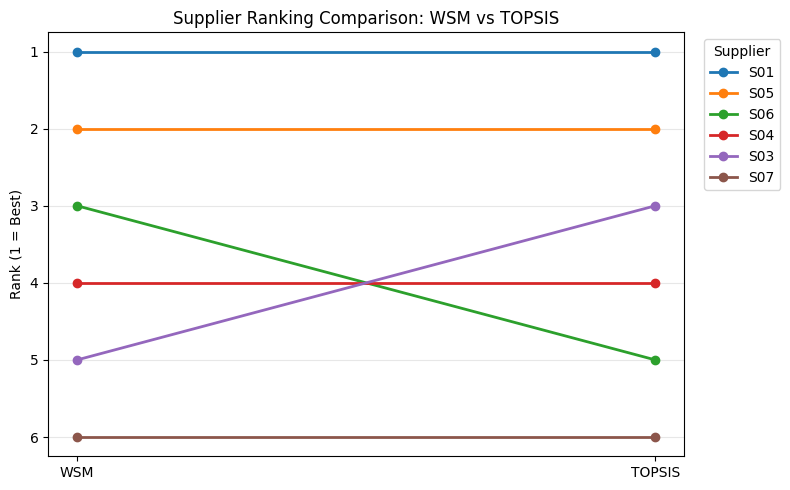

In [ ]:

# STEP 6B: VISUALIZE BASE RANKING COMPARISON

import matplotlib.pyplot as plt

rank_comparison = pd.DataFrame({
    "WSM": wsm_base["WSM rank"],
    "TOPSIS": topsis_base["TOPSIS rank"]
}).sort_values("WSM")

fig, ax = plt.subplots(figsize=(8, 5))

for supplier, row in rank_comparison.iterrows():
    ax.plot(
        ["WSM", "TOPSIS"],
        [row["WSM"], row["TOPSIS"]],
        marker="o",
        linewidth=2,
        label=supplier
    )

ax.set_title("Supplier Ranking Comparison: WSM vs TOPSIS")
ax.set_ylabel("Rank (1 = Best)")
ax.set_yticks(range(1, len(rank_comparison) + 1))
ax.invert_yaxis()
ax.grid(axis="y", alpha=0.3)
ax.legend(title="Supplier", bbox_to_anchor=(1.02, 1),
          loc="upper left")

plt.tight_layout()
plt.savefig(
    "01_WSM_TOPSIS_Ranking.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()